# Liouville space: the spherical-tensor formalism

This guide covers the `sphten-liouv` formalism: Liouville space built on
products of irreducible spherical tensors, with the state-space restriction
that lets Spinach simulate large spin systems. Read
[Liquid-state NMR in Hilbert space](hilbert-space.ipynb) first; `create`,
`assume`, the experiment parameters and the processing are the same. The
companion notebook is
[`notebooks/liouville-space.ipynb`](liouville-space.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/liouville-space.ipynb)).

Ported: the basis set with its restrictions, operators (superoperators),
states, the Hamiltonian and kinetics superoperators, the analytical
filters, and propagation with trajectory-level reduction (`step`,
`evolution`, `liquid`), so pulse-acquire experiments and chemical
exchange run end to end.

Every Python block is executed by `tests/docs/`, in order and in one
namespace.

*Generated from [`docs/liouville-space.md`](../liouville-space.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Why Liouville space](#Why-Liouville-space)
2. [The basis descriptor](#The-basis-descriptor)
3. [State-space restriction](#State-space-restriction)
4. [Filters](#Filters)
5. [Chemical subsystems](#Chemical-subsystems)
6. [Operators: superoperators in the restricted basis](#Operators:-superoperators-in-the-restricted-basis)
7. [States](#States)
8. [The Liouvillian: Hamiltonian and kinetics superoperators](#The-Liouvillian:-Hamiltonian-and-kinetics-superoperators)
9. [Analytical filters](#Analytical-filters)
10. [Propagation: `step`, `evolution`, and the reductions](#Propagation:-step,-evolution,-and-the-reductions)
11. [Pulse-acquire and chemical exchange through `liquid`](#Pulse-acquire-and-chemical-exchange-through-liquid)
12. [What is not ported yet](#What-is-not-ported-yet)
13. [Checking results against Spinach](#Checking-results-against-Spinach)

## Why Liouville space

In Hilbert space the density matrix of `n` spin-1/2 particles has `4^n`
elements and nothing can be left out. In Liouville space the density matrix
is a vector in the space of operators, and a basis of that space can be
chosen so that each basis operator has a physical label: how many spins it
correlates and what coherence order it carries. Spinach's observation
(Kuprov et al. 2007; Karabanov et al. 2011) is that in liquid-state NMR
high spin correlations are never populated to a significant extent, so
dropping them makes the matrix dimension polynomial rather than exponential
in the number of spins, while relaxation and kinetics superoperators can be
added to the same generator.

In [1]:
import numpy as np
import spynach


def make_spin_system(isotopes, **inter):
    return spynach.create({"isotopes": isotopes, "magnet": 14.1}, inter)

## The basis descriptor

Each spin of multiplicity `2S + 1` has `(2S + 1)^2` single-spin irreducible
spherical tensor operators `T(l, m)`, numbered by the linear index
`l*l + l - m`: 0 is the unit operator, 1, 2, 3 are `T(1,+1)`, `T(1,0)`,
`T(1,-1)` (proportional to `L+`, `Lz`, `L-`), 4 to 8 the rank-2 tensors of a
spin-1, and so on. A basis state is a product of one tensor per spin,
normalised to unit Frobenius norm, and is described by one integer per spin.
`basis()` stores all of them as the rows of `spin_system.basis.basis`, sorted
lexicographically with the all-zero unit state first:

In [2]:
spin_system_ab = spynach.basis(make_spin_system(["1H", "1H"]), {"formalism": "sphten-liouv", "approximation": "none"})
print(spin_system_ab.basis.nstates)  # (2*2)^2: the complete Liouville space
print(spin_system_ab.basis.basis.T)  # column 6 is T(1,+1) on spin 0 times T(1,0) on spin 1

16
[[0 0 0 0 1 1 1 1 2 2 2 2 3 3 3 3]
 [0 1 2 3 0 1 2 3 0 1 2 3 0 1 2 3]]


Two labels are derived from the descriptor and used by the filters below:
`tot_proj`, the total coherence order (sum of `m` over spins), and
`tot_cord`, the spin correlation order (number of spins carrying a
non-unit tensor):

In [3]:
print(spin_system_ab.basis.tot_proj)
print(spin_system_ab.basis.tot_cord)
spin_system_hd = spynach.basis(make_spin_system(["1H", "2H"]), {"formalism": "sphten-liouv", "approximation": "none"})
print(spin_system_hd.basis.nstates)  # 4 * 9: spin-1 has nine tensors, ranks 0 to 2

[ 0  1  0 -1  1  2  1  0  0  1  0 -1 -1  0 -1 -2]
[0 1 1 1 1 2 2 2 1 2 2 2 1 2 2 2]
36


## State-space restriction

`bas["approximation"]` chooses which states are kept. The complete basis
(`'none'`) is practical up to about ten spins; beyond that, Spinach's
"IK" basis sets keep only correlations between spins that are coupled to
each other. All of them are unions of complete bases of small subgraphs of
the coupling graph, so every state in them is a product of tensors on a
few coupled spins and the unit operator elsewhere.

| approximation | keeps | parameters |
|---|---|---|
| `none` | everything | |
| `IK-0` | all correlations of up to `inter_level` spins, regardless of coupling | `inter_level` |
| `IK-1` | correlations of up to `inter_level` spins connected through the coupling graph, and of up to `prox_level` spatially proximate spins | `inter_level`, `prox_level`, `connectivity` |
| `IK-2` | each spin together with all spins directly coupled to it, plus proximity correlations up to `prox_level` | `prox_level`, `connectivity` |

`connectivity` is `'scalar_couplings'` (the isotropic coupling builds the
graph) or `'full_tensors'` (the full tensor norm does); a coupling counts
when its norm exceeds `tols.inter_cutoff`. Spatial proximity needs atomic
coordinates, which are not ported, so for now no spins are proximate and
`prox_level` only has to be present.

For `n` spin-1/2 particles, `IK-0` at level `k` keeps
`sum_j C(n, j) 3^j` for `j <= k` states; with `IK-1` and `IK-2` the count
depends on the coupling topology. A chain with nearest-neighbour couplings
shows the difference:

In [4]:
spin_system_five = make_spin_system(["1H"] * 5)
for level in (1, 2, 3, 5):
    spin_system_ik0 = spynach.basis(
        spin_system_five, {"formalism": "sphten-liouv", "approximation": "IK-0", "inter_level": level}
    )
    print(f"IK-0 level {level}: {spin_system_ik0.basis.nstates} states")

J = np.zeros((8, 8))
for n in range(7):
    J[n, n + 1] = 10.0  # nearest-neighbour couplings only
spin_system_chain = make_spin_system(["1H"] * 8, coupling={"scalar": J.tolist()})
spin_system_ik2 = spynach.basis(
    spin_system_chain,
    {"formalism": "sphten-liouv", "approximation": "IK-2", "connectivity": "scalar_couplings", "prox_level": 1},
)
spin_system_ik1 = spynach.basis(
    spin_system_chain,
    {
        "formalism": "sphten-liouv",
        "approximation": "IK-1",
        "connectivity": "scalar_couplings",
        "inter_level": 4,
        "prox_level": 1,
    },
)
print(f"8-spin chain: complete {4**8}, IK-2 {spin_system_ik2.basis.nstates}, IK-1(4) {spin_system_ik1.basis.nstates}")
print(
    f"highest correlation order: IK-2 {spin_system_ik2.basis.tot_cord.max()}, "
    f"IK-1(4) {spin_system_ik1.basis.tot_cord.max()}"
)  # a chain spin has at most two neighbours

IK-0 level 1: 16 states
IK-0 level 2: 106 states
IK-0 level 3: 376 states
IK-0 level 5: 1024 states
8-spin chain: complete 65536, IK-2 304, IK-1(4) 1024
highest correlation order: IK-2 3, IK-1(4) 4


The states kept by `IK-2` on the chain are products on up to three
consecutive spins. The correlation-order histogram makes the restriction
visible:

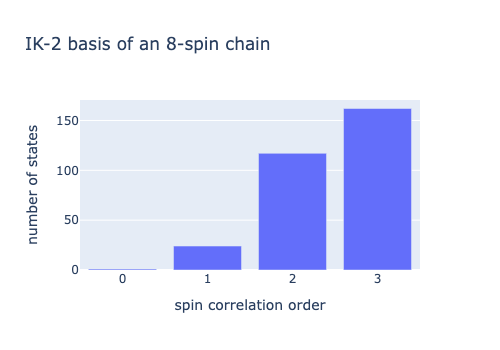

In [5]:
import plotly.graph_objects as go

orders, counts = np.unique(spin_system_ik2.basis.tot_cord, return_counts=True)
fig = go.Figure(go.Bar(x=orders, y=counts))
fig.update_layout(
    title="IK-2 basis of an 8-spin chain",
    xaxis_title="spin correlation order",
    yaxis_title="number of states",
    width=500,
    height=350,
)
fig

## Filters

Three filters remove states that a given experiment never populates; each
is a list with one entry per chemical subsystem (see below), so for a
single molecule they are lists of one element.

- `projections`: coherence orders to keep. The unit state is always kept.
  A pulse-acquire experiment on an ideal 90-degree pulse only needs
  `[+1]` (or `[-1]`, depending on the detection convention).
- `longitudinal`: spins (0-based numbers or an isotope name) that only
  carry `m = 0` tensors, for example undetected heteronuclei in a
  proton experiment.
- `zero_quantum`: spins whose total coherence order must be zero.

In [6]:
spin_system_hc = make_spin_system(
    ["1H", "13C"], zeeman={"scalar": [2.0, 30.0]}, coupling={"scalar": [[0, 145.0], [0, 0]]}
)
spin_system_full = spynach.basis(spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none"})
spin_system_plus_one = spynach.basis(
    spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none", "projections": [[1]]}
)
spin_system_carbon_z = spynach.basis(
    spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none", "longitudinal": [["13C"]]}
)
spin_system_carbon_zq = spynach.basis(
    spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none", "zero_quantum": [[1]]}
)
for name, s in [
    ("complete", spin_system_full),
    ("projections +1", spin_system_plus_one),
    ("longitudinal 13C", spin_system_carbon_z),
    ("zero-quantum 13C", spin_system_carbon_zq),
]:
    print(f"{name}: {s.basis.nstates} states, coherence orders {sorted(set(s.basis.tot_proj.tolist()))}")

complete: 16 states, coherence orders [-2, -1, 0, 1, 2]
projections +1: 5 states, coherence orders [0, 1]
longitudinal 13C: 8 states, coherence orders [-1, 0, 1]
zero-quantum 13C: 8 states, coherence orders [-1, 0, 1]


`bas["manual"]` adds subgraphs of your own: a boolean matrix with one row
per subgraph and one column per spin, whose complete product bases are
added to whatever the approximation generates.

In [7]:
spin_system_manual = spynach.basis(
    spin_system_chain,
    {
        "formalism": "sphten-liouv",
        "approximation": "IK-0",
        "inter_level": 1,
        "manual": [[True, False, False, False, False, False, False, True]],
    },
)
print(spin_system_manual.basis.nstates)  # 1 + 8 * 3 + 9: singles, plus the two-spin states on spins 0 and 7

34


## Chemical subsystems

A spin system with several molecules (`inter["chem"]["parts"]`, see the
[Hilbert-space guide](hilbert-space.ipynb#1.-create:-describe-the-spin-system))
gets one sub-basis per molecule; the sub-bases share the unit state and
nothing else, because operators and states never correlate spins of
different molecules. This is the layout Spinach's kinetics superoperator
relies on: with identical molecules on both sides of a reaction, the
sub-bases are identical blocks and exchange maps each state of one onto
the same state of the other.

In [8]:
spin_system_exchange = make_spin_system(
    ["1H", "1H"],
    zeeman={"scalar": [0.0, 3.0]},
    chem={"parts": [[0], [1]], "rates": [[-2e3, 2e3], [2e3, -2e3]], "concs": [1.0, 1.0]},
)
spin_system_two_sites = spynach.basis(spin_system_exchange, {"formalism": "sphten-liouv", "approximation": "none"})
print(spin_system_two_sites.basis.basis.T)  # 7 states, 1 + 3 + 3, not 16

[[0 0 0 0 1 2 3]
 [0 1 2 3 0 0 0]]


Filters are specified per molecule: `projections=[[1], [1]]` keeps the
`+1` coherences of both sites.

## Operators: superoperators in the restricted basis

In Liouville space an operator `Q` acts on the density matrix from the
left (`Q rho`), from the right (`rho Q`), as a commutator (`[Q, rho]`, what
Hamiltonians do) or as an anticommutator. `operator(spin_system, ops, spins,
operator_type)` returns the chosen superoperator as a sparse
`nstates x nstates` matrix; `operator_type` is `'left'`, `'right'`,
`'comm'` (the default, as in Spinach) or `'acomm'`. The operator
descriptions are the same as in Hilbert space:

In [9]:
spin_system_ab_hilb = spynach.basis(
    make_spin_system(["1H", "1H"]), {"formalism": "zeeman-hilb", "approximation": "none"}
)
Lz_comm = spynach.operator(spin_system_ab, "Lz", "1H")  # [Lz, .] on both protons
Lz_left = spynach.operator(spin_system_ab, "Lz", "1H", "left")
Lz_right = spynach.operator(spin_system_ab, "Lz", "1H", "right")

Nothing is ever expanded into the full `dim^2 x dim^2` space: the product
of two spherical tensors on one spin is a fixed linear combination of
spherical tensors on that spin (`spynach.operators.ist_product_table`), so
the action on a product state factorises over the spins and the matrix
elements are looked up directly in the basis descriptor. In a restricted
basis the result is the exact superoperator projected onto the kept
states; states that an operator would create outside the basis are simply
dropped. The matrix elements themselves can be checked against the
Hilbert-space definition, `A[k, j] = <B_k | Q B_j>` for the orthonormal
basis operators `B_k`:

In [10]:
from spynach.operators import irr_sph_ten, lin2lm


def basis_operator(spin_system, row):
    t = np.array([[1.0 + 0j]])
    for mult, index in zip(spin_system.mults, row):
        rank, proj = lin2lm(int(index))
        t = np.kron(t, irr_sph_ten(int(mult), rank)[rank - proj].toarray())
    return t / np.sqrt(np.vdot(t, t).real)


B = [basis_operator(spin_system_ab, row) for row in spin_system_ab.basis.basis]
Q = spynach.operator(spin_system_ab_hilb, "Lz", "1H").toarray()
reference = np.array([[np.vdot(bk, Q @ bj) for bj in B] for bk in B])
print(abs(Lz_left.toarray() - reference).max())

1.1102230246251565e-16


## States

`state(spin_system, ops, spins, method)` returns a dense complex vector of
coefficients in the orthonormal basis; its first element is the
coefficient of the unit state. Spinach's three methods are available:

- `'exact'` (default): the operator applied to the unit state, which is
  the expansion of `Op / sqrt(dim)`. A spin-1/2 `Lz` has coefficient 1/2 on
  its `T(1,0)` state, `L+` has `-1/sqrt(2)` on `T(1,+1)`.
- `'cheap'`: the coefficients placed directly on the basis states (`Lz`
  gives 1, `L+` gives `-sqrt(2)`); an error if the state is not in the
  basis. For products of `p` spin-1/2 operators the two differ by `2^p`.
- `'chem'`: `'exact'` weighted by the concentration of the molecule each
  term belongs to, for exchanging systems.

In [11]:
rho_exact = spynach.state(spin_system_ab, "Lz", "1H")
rho_cheap = spynach.state(spin_system_ab, "Lz", "1H", "cheap")
print(np.flatnonzero(rho_exact), rho_exact[rho_exact != 0])
print(np.flatnonzero(rho_cheap), rho_cheap[rho_cheap != 0])
coil = spynach.state(spin_system_ab, "L+", "1H")
weighted = spynach.state(spin_system_two_sites, "L+", "1H", "chem")
print(np.flatnonzero(weighted), weighted[weighted != 0])  # one T(1,+1) state per site

[2 8] [0.5+0.j 0.5+0.j]
[2 8] [1.+0.j 1.+0.j]
[1 4] [-0.70710678+0.j -0.70710678+0.j]


Expectation values are Frobenius products, `spynach.hdot(coil, rho)`, so
the observable of a `'exact'` state against a `'exact'` coil carries a
factor `1/dim` relative to the Hilbert-space trace; Spinach has the same
convention, and only ratios of observables matter in practice.

## The Liouvillian: Hamiltonian and kinetics superoperators

`hamiltonian(spin_system, operator_type)` uses the same term table as in Hilbert
space (`assume` first) and returns, by default, the commutation
superoperator `[H, .]`, the generator of coherent evolution. The
rotating-frame offsets of `frqoffset` are added as `2 pi offset [Lz, .]`:

In [12]:
spin_system_hc_nmr = spynach.assume(
    spynach.basis(spin_system_hc, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr"
)
H = spynach.hamiltonian(spin_system_hc_nmr)
H_off = spynach.frqoffset(spin_system_hc_nmr, H, {"spins": ["1H"], "offset": [1200.0]})
Lz_comm_H = spynach.operator(spin_system_hc_nmr, "Lz", "1H")

A commutation superoperator is traceless and its eigenvalues are
differences of Hamiltonian eigenvalues, so the coherence frequencies of
the spectrum can be read off directly; as a check against the Hilbert-space
Hamiltonian:

In [13]:
spin_system_hc_hilb = spynach.assume(
    spynach.basis(spin_system_hc, {"formalism": "zeeman-hilb", "approximation": "none"}), "nmr"
)
E = np.linalg.eigvalsh(np.asarray(spynach.hamiltonian(spin_system_hc_hilb)))
differences = np.sort((E[:, None] - E[None, :]).ravel())
print(np.allclose(np.sort(np.linalg.eigvals(np.asarray(H)).real), differences, atol=1e-6))

True


In a restricted basis the Liouvillian is the projection of the complete
one onto the kept states; Karabanov et al. (2011) show that the error this
makes decays as a Gaussian in the correlation order for liquid-state NMR.

`kinetics(spin_system)` builds the first-order exchange superoperator from
`inter["chem"]["rates"]`: every state of one molecule is mapped onto the
identical state of the other at the given rate, the diagonal rates drain
the source states, and the unit state is untouched. It enters the
Liouvillian as `L = H + 1j * R + 1j * K`, Spinach's convention for
dissipative superoperators:

In [14]:
spin_system_two_sites_nmr = spynach.assume(spin_system_two_sites, "nmr")
K = spynach.kinetics(spin_system_two_sites_nmr)
L = spynach.hamiltonian(spin_system_two_sites_nmr) + 1j * K

`equilibrate(rates, concs)` is Spinach's helper for the concentrations
the kinetics relax to: it keeps the total of every connected group of
reactions and solves `K c = 0`, so it is the natural sanity check (or
source) of `inter["chem"]["concs"]`:

In [15]:
rates = np.array([[-50.0, 950.0], [50.0, -950.0]])
print(spynach.equilibrate(rates, np.array([0.5, 0.5])))

[0.95 0.05]


## Analytical filters

In this basis the correlation order and the coherence order of every
state are labels of the descriptor, so selecting coherences (what phase
cycles do in the spectrometer) is a matter of zeroing coefficients.
`correlation(spin_system, rho, orders, spins)` keeps the states whose number of
correlated spins (among `spins`) is in `orders`; `coherence(spin_system, rho,
spec)` keeps the states whose total coherence order over each spin set in
`spec` is in the listed orders. Both accept arrays with the spin state
space on the last axis, so they work on stacks of state vectors too.

In [16]:
rho = spynach.state(spin_system_hc_nmr, "L+", "all") + spynach.state(spin_system_hc_nmr, ["Lz", "L+"], [0, 1])
single = spynach.correlation(spin_system_hc_nmr, rho, [1])
print(np.flatnonzero(single))  # L+ on 1H and on 13C
proton = spynach.coherence(spin_system_hc_nmr, rho, [("1H", [1]), ("13C", [0])])
print(np.flatnonzero(proton))  # only L+ on the proton
stack = np.stack([rho, 2 * rho])
print(spynach.correlation(spin_system_hc_nmr, stack, [2]).shape)

[1 4]
[4]
(2, 16)


## Propagation: `step`, `evolution`, and the reductions

A Liouville-space state is a vector, so one time step is a
matrix-vector product with `expm(-1j * L * dt)`. `step(spin_system, L, rho, dt)`
computes it without forming the exponential: a Taylor series of the
generator acting on the vector, in substeps short enough for the series
to converge quickly. It takes a single vector or a stack of column
vectors, and a list of two or three generators sampled across the step
(the Lie-group quadratures Spinach uses for shaped pulses):

In [17]:
import scipy.linalg as sla

L = spynach.frqoffset(
    spin_system_hc_nmr, spynach.hamiltonian(spin_system_hc_nmr), {"spins": ["1H"], "offset": [1200.0]}
)
rho = spynach.state(spin_system_hc_nmr, "L+", "1H")
dt = 1e-3
rho_dt = spynach.step(spin_system_hc_nmr, L, rho, dt)
print(np.abs(rho_dt - sla.expm(-1j * np.asarray(L) * dt) @ rho).max())

1.6653401838144757e-16


`evolution(spin_system, L, rho, dt, nsteps, output, coil=...)` runs a whole free
evolution period (the detection state `coil` is a keyword argument, needed
only by the `'observable'` and `'multichannel'` outputs). Before propagating, it reduces the problem exactly for
the trajectory at hand (`spynach.reduce`):

- **destination state screening** (Krzystyniak et al. 2011): for the
  `'observable'` output the reduction is run backwards from the coil
  state, since only states that can reach the detector matter;
- **zero track elimination** (Kuprov 2008, `spynach.zte`): a short trial
  propagation marks the states that are ever populated above
  `tols.zte_tol`; the others are dropped;
- **path tracing** (Hogben et al. 2010, `spynach.path_trace`): the
  generator is split into non-interacting subspaces (connected components
  of its graph), unpopulated ones are dropped, small ones merged into
  batches of `tols.merge_dim` states. Skipped below `tols.merge_dim`
  states.

Each subspace is then propagated with the exponential propagator, or, above
`tols.krylov_tol` states, by repeated `step` calls (`spynach.krylov`).
`sys["disable"]` accepts Spinach's `'zte'`, `'pt'`, `'dss'`, `'merge'`,
`'krylov'` and `'trajlevel'` tokens, `sys["enable"]` accepts `'krylov'`;
none of them changes the answer:

In [18]:
coil = spynach.state(spin_system_hc_nmr, "L+", "1H")
fid = spynach.evolution(spin_system_hc_nmr, L, rho, 1 / 500, 63, "observable", coil=coil)
spin_system_hc_plain = spynach.create(
    {"isotopes": ["1H", "13C"], "magnet": 14.1, "disable": ["trajlevel"]},
    {"zeeman": {"scalar": [2.0, 30.0]}, "coupling": {"scalar": [[0, 145.0], [0, 0]]}},
)
spin_system_hc_plain = spynach.assume(
    spynach.basis(spin_system_hc_plain, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr"
)
fid_plain = spynach.evolution(spin_system_hc_plain, L, rho, 1 / 500, 63, "observable", coil=coil)
print(np.abs(fid - fid_plain).max())
projectors = spynach.reduce(spin_system_hc_nmr, L.conj().T, coil)
print([p.shape[1] for p in projectors])  # L+(H) and L+(H)Lz(C) are all that reaches the coil

trajectory level state space restriction disabled by user.


7.731808680624462e-15
[2]


Outputs: `'observable'` returns `coil^H rho(t)` at `nsteps + 1` points
(a `(nsteps + 1, k)` array for a stack of `k` vectors), `'final'` the
state after `nsteps` steps, `'trajectory'` the `(nstates, nsteps + 1)`
array of states. Because `'exact'` states carry a factor `1/sqrt(dim)`
each, a Liouville-space observable is the Hilbert-space one divided by
`dim`:

In [19]:
spin_system_hc_hilb_nmr = spynach.assume(
    spynach.basis(spin_system_hc, {"formalism": "zeeman-hilb", "approximation": "none"}), "nmr"
)
L_hilb = spynach.frqoffset(
    spin_system_hc_hilb_nmr, spynach.hamiltonian(spin_system_hc_hilb_nmr), {"spins": ["1H"], "offset": [1200.0]}
)
rho_hilb = spynach.state(spin_system_hc_hilb_nmr, "L+", "1H")
fid_hilb = spynach.evolution(spin_system_hc_hilb_nmr, L_hilb, rho_hilb, 1 / 500, 63, "observable", coil=rho_hilb)
print(np.abs(4 * fid - fid_hilb).max())

4.606160526853057e-13


Two tools of Spinach's look at states and trajectories in this basis.
`trajan(spin_system, traj, property)` returns, for every class of basis states
(`"correlation_order"`, `"coherence_order"`, `"total_each_spin"`,
`"local_each_spin"`), the 2-norm of the trajectory restricted to that
class at every point, with the unit state projected out, plus the legend
text of the rows; `spynach.plotting.plot_trajan` draws it against a
time axis. `stateinfo(spin_system, rho, n)` lists the `n` largest coefficients of
a state with the `(l, m)` of every spin, as Spinach reports them:

In [20]:
traj = spynach.evolution(spin_system_hc_nmr, L, rho, 1 / 500, 63, "trajectory")
amplitudes, labels = spynach.trajan(spin_system_hc_nmr, traj, "coherence_order")
print(labels, amplitudes[:, 0].round(3))  # L+(H) starts as pure +1 coherence
largest = spynach.stateinfo(spin_system_hc_nmr, traj[:, -1], 2)
print(largest)

['-2', '-1', '0', '+1', '+2'] [0.    0.    0.    0.707 0.   ]
[(((1, 1), (1, 0)), (-0.2737105458063936+0.4543301063149901j), 6), (((1, 1), (0, 0)), (-0.40054586879967774-0.24130830611002063j), 4)]


## Pulse-acquire and chemical exchange through `liquid`

`liquid` builds `H`, `R` (zero: relaxation is not ported) and `K`
(`spynach.kinetics`) and hands them to the pulse sequence, which forms the
Liouvillian as `L = H + 1j * R + 1j * K`; `acquire` then calls
`evolution`. For an exchanging system the initial state is weighted by
the concentrations (`state(..., "chem")`) and the coil is not, exactly as
in Spinach's `examples/kinetics/exchange_symmetric.m`:

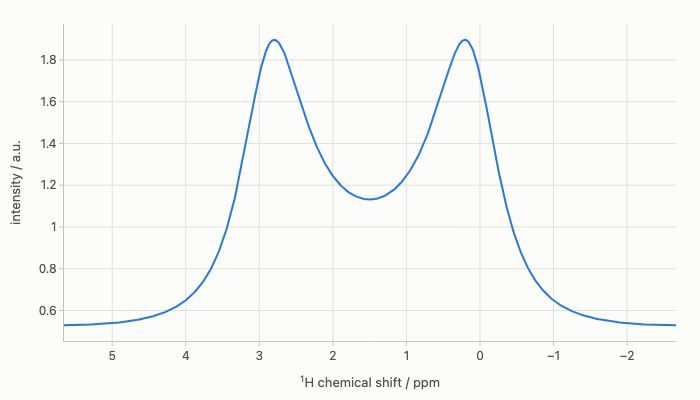

In [21]:
from spynach.plotting import plot_1d

exch_pars = {
    "spins": ["1H"],
    "offset": 900.0,
    "sweep": 5000.0,
    "npoints": 512,
    "zerofill": 1024,
    "rho0": spynach.state(spin_system_two_sites, "L+", "1H", "chem"),
    "coil": spynach.state(spin_system_two_sites, "L+", "1H"),
    "axis_units": "ppm",
    "invert_axis": True,
}
fid_exch = spynach.liquid(spin_system_two_sites, spynach.acquire, exch_pars, "nmr")
fid_exch *= np.exp(-6 * np.arange(exch_pars["npoints"]) / exch_pars["npoints"])  # exponential apodisation
spectrum_exch = np.fft.fftshift(np.fft.fft(fid_exch, exch_pars["zerofill"]))
plot_1d(spin_system_two_sites, spectrum_exch.real, exch_pars)

The two lines at 0 and 3 ppm, 1800 Hz apart at 14.1 T, exchange at
2000 Hz: close to coalescence, they merge into one broad line. The same
FID follows the McConnell equations of the two sites, which
`tests/unit/test_propagation_liouv.py` checks against a `2 x 2` matrix
exponential.

## What is not ported yet

- the `evolution` output `'total'`, Lie-group quadratures in Hilbert
  space, magnetisation flux and radical-pair kinetics, homodecoupling
  operators other than through `acquire`;
- permutation symmetry (`sym_group`, `sym_spins`);
- the `zeeman-liouv` formalism, and the `IK-DNP` and `IK-SBS` basis sets.

Relaxation, anisotropic interactions with coordinates, magic angle
spinning and the 2-D sequences have their own guides.

## Checking results against Spinach

Everything on this page is checked in two ways. `tests/unit/` compares
the superoperators with direct Frobenius products of the Hilbert-space
operators (`<B_k | Q B_j>`), which needs no reference data and holds to
1e-15 for operators and to the `liouv_zero` rounding grid (1e-10 rad/s)
for Hamiltonians. `tests/slice/test_liouv_setup_parity.py` compares the
basis descriptors, product tables, superoperators, states, Hamiltonians,
kinetics and filters of twelve reference cases, and
`tests/slice/test_liouv_pa_parity.py` the propagators, steps, reductions,
`evolution` outputs and pulse-acquire FIDs of nine (including two-site
exchange, and cases with the Krylov path and path tracing forced), with
the output of Spinach 2.13 stored as fixtures (`oracle/README.md`,
requests FR-002 and FR-003 in `porting/FIXTURE_REQUESTS.md`); those tests
skip while the fixtures are absent. Measured agreement (largest
elementwise difference relative to the largest element):

| stage | difference from Spinach |
|---|---|
| basis descriptors, coherence and correlation orders | 0 |
| product tables: spin-1/2 | 0 |
| product tables: spin-1 | 2e-16 |
| superoperators (all four types, 5 to 11 441 states) | 2e-16, identical sparsity |
| states (`exact`, `cheap`, `chem`) | 0 |
| Hamiltonian superoperators and offsets | 2e-14 |
| kinetics superoperators | 0 |
| `correlation` and `coherence` | 0 |
| Liouvillians `H + iK` with offsets | 2e-14 |
| dwell-time propagators (16 to 1789 states) | 2e-14 |
| `step` over one and over 7.3 dwell times | 1e-16, 7e-16 |
| zero-track and `reduce` projectors | identical sets of kept states |
| `evolution`: `observable`, `final`, `trajectory` | 3e-13, 8e-13, 5e-14 |
| `liquid`/`acquire` FIDs and spectra (256 to 512 points) | 3e-13, 8e-13 |

The Hamiltonian figure is the same `liouv_zero` grid effect as in Hilbert
space: Spinach sums the terms in random order before rounding, so single
elements can land one grid step (1e-10 rad/s) away.